## 🧪 Task 1: Frequency Tables & Dot Plots — Discretizing Continuous Features

**Title & Scenario:** You are working for an e-commerce platform and want to understand the distribution of customer purchase amounts. Because purchase amounts are continuous, you need to discretize them into meaningful bins to understand common spending tiers.

**Learning Objectives:** Building frequency tables from raw continuous data, creating dot plots to visualize discrete counts, and understanding the trade-off between bin granularity and information loss.

**ML Connection:** Many ML models (like Naive Bayes or Decision Trees) sometimes benefit from *binned* (discretized) features rather than raw continuous ones. Frequency tables are the first step in deciding bin boundaries for feature engineering.

### Step-by-Step Analytical Instructions

1. **Load the Titanic dataset using Seaborn and drop rows with missing `fare` values.**
   - **Medieval Fantasy Lens:** Imagine the dataset as a kingdom’s tax ledger. Rows with missing fare are torn pages or ink-smudged entries. Dropping them is like deciding to count only the intact scrolls so the royal census does not invent false taxpayers.  
   - **Purpose:** Establish a clean, trustworthy foundation before any tallying begins.

2. **Round the `fare` column to the nearest integer to create discrete observations.**
   - **Medieval Fantasy Lens:** Exact fares are like mixed coin pouches — 7 gold, 8 silver, 3 copper. Rounding turns them into whole gold coins, which the castle clerk can tally more easily.  
   - **Purpose:** Convert a continuous feature into discrete values so frequencies and dot plots become possible.

3. **Build a frequency table using Pandas that counts the occurrences of each rounded fare value, sorted by the fare amount.**
   - **Medieval Fantasy Lens:** This is the clerk’s tally sheet: “How many travelers paid 7 gold? How many paid 8 gold?” It turns a chaotic pile of receipts into a readable roll call.  
   - **Purpose:** Summarize the distribution and reveal common spending tiers.

4. **Create a dot plot manually using Matplotlib. For each unique fare value in your frequency table, plot a stack of dots vertically. The x-axis is the fare value, the y-axis is the frequency (count).**
   - **Medieval Fantasy Lens:** Picture a tavern wall where each customer is represented by a nail above the amount they paid. A stack of nails at 10 gold means many customers paid that exact amount.  
   - **Purpose:** Preserve every observation’s identity while still showing the overall shape of the distribution.

5. **Repeat the process, but this time group the fares into bins of width 10 (e.g., 0–10, 11–20). Compare the visual readability of the two plots.**
   - **Medieval Fantasy Lens:** Instead of one nail per exact coin, you group payments into chests: 0–10 gold, 11–20 gold, and so on. The wall chart becomes less cluttered, like summarizing many small villages into provinces.  
   - **Purpose:** Trade fine-grained detail for readability, which is also useful when deciding how to engineer binned features for ML models.

**Expected Output/Visualization:** A printed frequency table showing fare values and their counts, followed by a dot plot with dots stacked vertically at various x-coordinates. The second plot will look much less cluttered.

**Key Takeaway:** Dot plots preserve every observation’s identity, but they don’t scale well to large datasets. Binning (discretizing) is a necessary compromise for both visualization and feature engineering.


In [147]:
import pandas as pd
import numpy as np
import seaborn as sns

In [148]:
### 1st step,load dataset
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [149]:
df.shape

(891, 15)

In [150]:
##1. Remove any rows where the fare column contains missing values.
df['fare'].dropna()

0       7.2500
1      71.2833
2       7.9250
3      53.1000
4       8.0500
        ...   
886    13.0000
887    30.0000
888    23.4500
889    30.0000
890     7.7500
Name: fare, Length: 891, dtype: float64

In [151]:
df = df.dropna(subset=['fare'])

In [152]:
### 2. **Round the `fare` column to the nearest integer to create discrete observations.**
df['fare'] = df['fare'].round().astype(int)
df['fare'].head()

0     7
1    71
2     8
3    53
4     8
Name: fare, dtype: int32

In [153]:
print(df['fare'].max())
print(df['fare'].min())

512
0


In [154]:
### 3. **Build a frequency table using Pandas that counts the occurrences of each rounded fare value, sorted by the fare amount.**
tab = df['fare'].value_counts().reset_index().sort_values(by='fare')
tab.head()

,fare,count
12,0,15
87,4,1
89,5,1
37,6,5
1,7,65


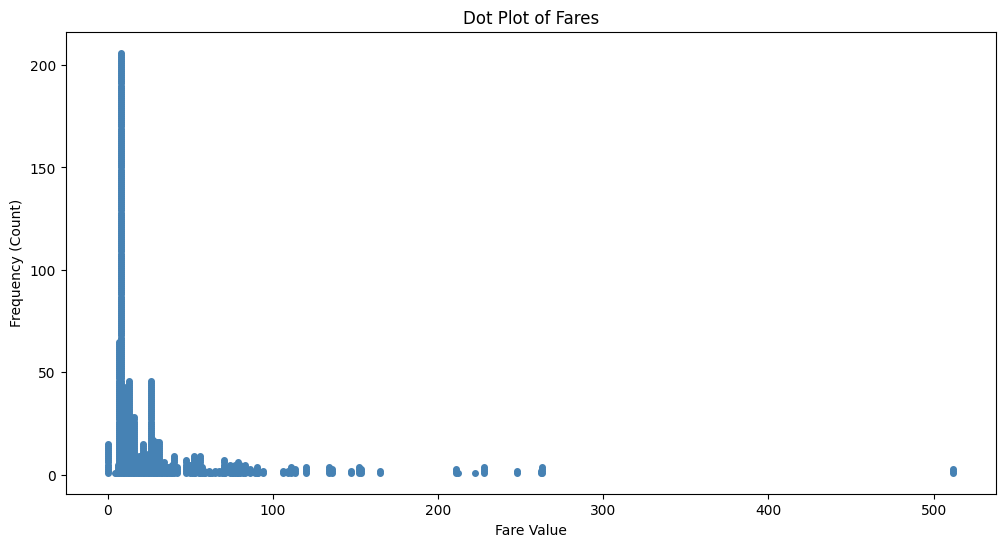

In [155]:
## 4. **Create a dot plot manually using Matplotlib. For each unique fare value in your frequency table, plot a stack of dots vertically. The x-axis is the fare value, the y-axis is the frequency (count).**

tab_sorted = tab.sort_values('fare')

import matplotlib.pyplot as plt

categories = list(tab_sorted['fare'].values)
values = list(tab_sorted['count'].values)

plt.figure(figsize=(12,6))
for fare,count in zip(tab_sorted['fare'],tab_sorted['count']):
    plt.plot([fare]*count,range(1,count+1),'o',color='steelblue',markersize=4)
plt.xlabel('Fare Value')
plt.ylabel('Frequency (Count)')
plt.title('Dot Plot of Fares')
plt.show()

In [164]:
bins = np.arange(0,df['fare'].max()+10,50)
df['fare_bin'] = pd.cut(df['fare'],bins=10)
df['fare_bin'] = pd.cut(df['fare'], bins=bins)

# df['fare_bin'] = pd.cut(df['fare'], bins=[0, 10, 20, 30, 50, 100,250,500],
#                         labels=['0-10', '10-20', '20-30', '30-50', '50-100','100-250','250-500'])

# df['fare_bin'] = pd.qcut(df['fare'], q=5)
bins

array([  0,  50, 100, 150, 200, 250, 300, 350, 400, 450, 500])

In [165]:
tab = df['fare_bin'].value_counts().sort_index().reset_index()
tab.columns = ['fare_bin','count']

In [166]:
tab

,fare_bin,count
0,"(0, 50]",717
1,"(50, 100]",106
2,"(100, 150]",24
3,"(150, 200]",9
4,"(200, 250]",11
5,"(250, 300]",6
6,"(300, 350]",0
7,"(350, 400]",0
8,"(400, 450]",0
9,"(450, 500]",0


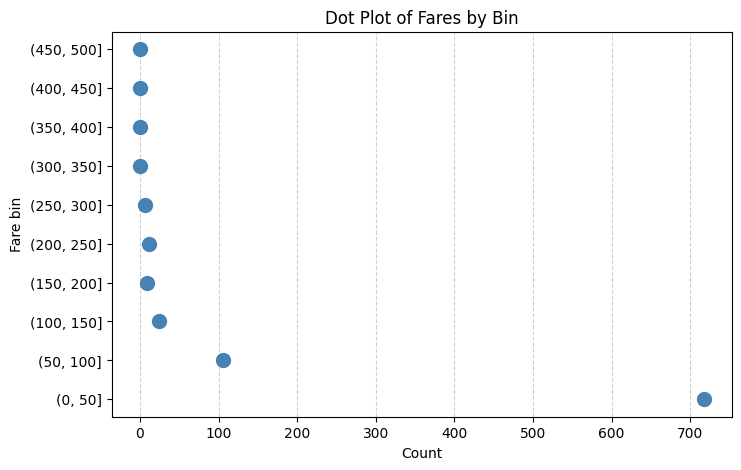

In [167]:
plt.figure(figsize=(8, 5))
plt.scatter(tab['count'], tab['fare_bin'].astype(str),
            color='steelblue', s=100, zorder=3)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.xlabel('Count')
plt.ylabel('Fare bin')
plt.title('Dot Plot of Fares by Bin')
plt.show()

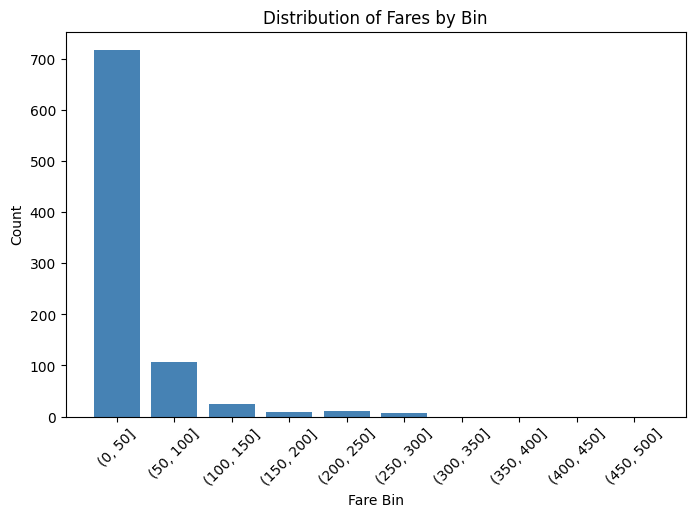

In [168]:
plt.figure(figsize=(8,5))
plt.bar(tab['fare_bin'].astype(str),tab['count'],color='steelblue')
plt.xlabel('Fare Bin')
plt.ylabel('Count')
plt.title('Distribution of Fares by Bin')
plt.xticks(rotation=45)
plt.show()

"My report on this matter indicates that the second approach—binning the wide range of values—is the best option for summarizing frequencies. This method makes it easy to see how many values fall between $0 and $7, $100 and $250, and so on. Conversely, the initial dot plot visualization makes it difficult to draw meaningful conclusions due to the sheer volume of dots; for reporting purposes, it is necessary to quantify or summarize them."